In [192]:
load("visualize.sage")
load("surfaces.sage")
load("curves.sage")
load("discriminants.sage")

# Plane curves

We consider a general curve $\mathbb P^2$ of degree $d$.

Ideal (-2*x0^4 - x0^3*x1 + 10*x0^2*x1^2 + 3*x1^4 + x0^3*x2 + 2*x0*x1^2*x2 - 2*x1^3*x2 + x0^2*x2^2 + 2*x0*x1*x2^2 - x1^2*x2^2 - x0*x2^3 - 2*x1*x2^3 + x2^4) of Multivariate Polynomial Ring in x0, x1, x2 over Rational Field


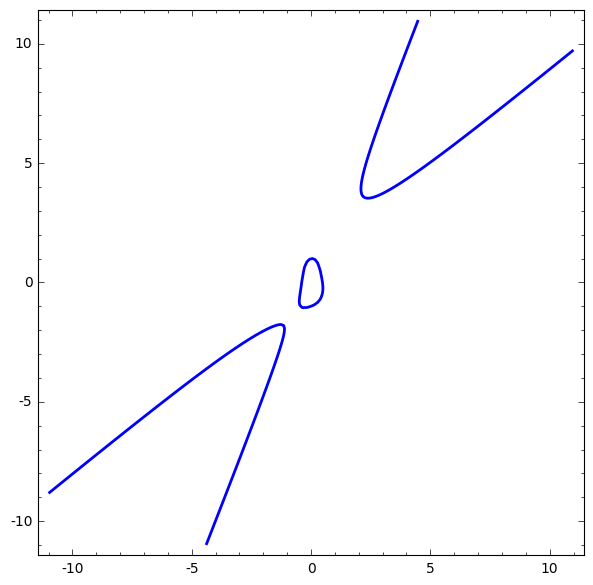

In [204]:
R.<x0,x1,x2> = QQ[]

degree = 4

F = general_curve(degree)
print F

g = plot_curve(F)
g.show()

### Inflectional and double tangents
We compute inflectional points and lines using the hessian determinant.

Number of complex flexes:  24
Number of real flexes:  2


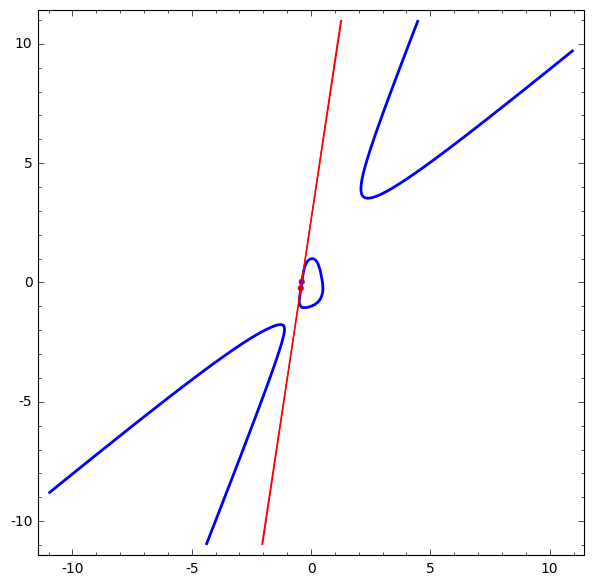

In [205]:
R.<x0,x1,x2> = QQ[]
flex_points_ideal = F + hessian_determinant(F)

print "Number of complex flexes: ", flex_points_ideal.hilbert_polynomial()

# real flex points:
real_flex_points = (flex_points_ideal.subs(x0=1).change_ring(QQ[x1, x2])).variety(RR)
print "Number of real flexes: ", len(real_flex_points)

# compute and show real flex lines
lines=tangents_at_points(F,real_flex_points)

g = plot_curve(F)
g += plot_lines(lines)
g += plot_points(real_flex_points)
g.show()

In [206]:
degree = 4

disc = discriminant_polynomial(degree)

nodal,cuspidal = nodal_and_cuspidal_discriminant_ideals(degree)
print nodal
print cuspidal

Defining a0, a1, a2, a3, a4, t
Defining a0, a1, a2, a3, a4, t
Ideal (a3^3 - 4*a2*a3*a4 + 8*a1*a4^2, a2*a3^2 - 4*a2^2*a4 + 2*a1*a3*a4 + 16*a0*a4^2, a1*a3^2 - 4*a1*a2*a4 + 8*a0*a3*a4, a0*a3^2 - a1^2*a4, a1^2*a3 - 4*a0*a2*a3 + 8*a0*a1*a4, a1^2*a2 - 4*a0*a2^2 + 2*a0*a1*a3 + 16*a0^2*a4, a1^3 - 4*a0*a1*a2 + 8*a0^2*a3) of Multivariate Polynomial Ring in a0, a1, a2, a3, a4 over Rational Field
Ideal (a2^2 - 3*a1*a3 + 12*a0*a4, a1*a2*a3 - 9*a0*a3^2 - 9*a1^2*a4 + 32*a0*a2*a4, a1^2*a3^2 - 3*a0*a2*a3^2 - 3*a1^2*a2*a4 + 28*a0*a1*a3*a4 - 128*a0^2*a4^2) of Multivariate Polynomial Ring in a0, a1, a2, a3, a4 over Rational Field


Number of complex double lines:  3*t + 31
Monoid of ideals of Multivariate Polynomial Ring in u0, u1, u2 over Rational Field
28
Number of real double lines:  8


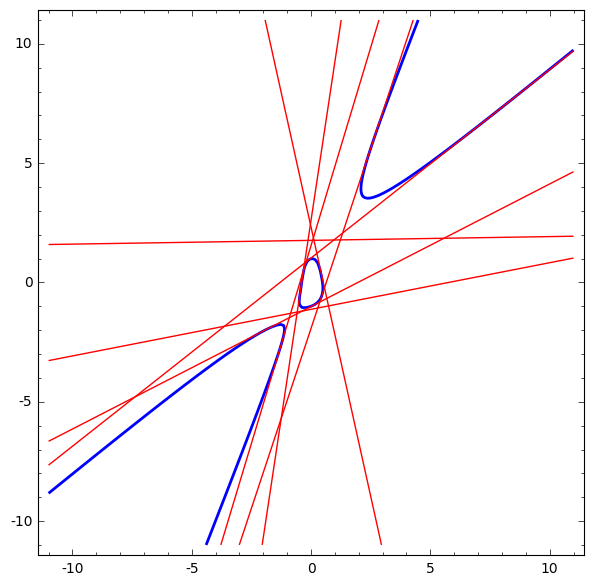

In [217]:
R2.<u0,u1,u2> = QQ[]
R3.<x0, x1, x2, u0, u1, u2, t> = QQ[]

# two points on u0x0+u1x1+u2x2=0
P = vector([-u1, u0, 0])
Q = vector([0, -u2, u1])

F1 = F.change_ring(R3)
poly = (F1.subs(x0=((P + t * Q)[0]), x1=((P + t * Q)[1]), x2=((P + t * Q)[2]))).gens()[0]

c=poly.polynomial(t).coefficients()

double_lines = nodal.subs(a0=c[0],a1=c[1],a2=c[2],a3=c[3],a4=c[4]) # change
double_lines = double_lines.change_ring(R2)

print "Number of complex double lines: ", double_lines.hilbert_polynomial()

print double_lines.parent()

R2.<u0,u1,u2> = QQ[]
double_lines = double_lines.saturation(ideal(u1))[0]

print double_lines.hilbert_polynomial()

real_double_lines = (double_lines.subs(u0=1).change_ring(QQ[u1, u2])).variety(RR)
print "Number of real double lines: ", len(real_double_lines)


lines = []
for l in real_double_lines:
    lines.append([1,l['u1'],l['u2']])

R.<x1,x2> = QQ[]
g = plot_curve(F)
for l in lines:
    line_equation = ideal(l[0] +l[1] *x1 +l[2] *x2).change_ring(RR[x1, x2])
    g += line_equation.plot(color='red')
g.show()


We find double lines, we first compute the *dual curve*.

In [ ]:
R2.<u0,u1,u2> = QQ[]
R3.<x0, x1, x2, u0, u1, u2, t> = QQ[]

# two points on u0x0+u1x1+u2x2=0
P = vector([-u1, u0, 0])
Q = vector([0, -u2, u1])

F1 = F.change_ring(R3)
poly = (F1.subs(x0=((P + t * Q)[0]), x1=((P + t * Q)[1]), x2=((P + t * Q)[2]))).gens()[0]
dual_curve = poly.resultant(poly.derivative(t), t)

# remove extra components that come from content respect to u0
dual_curve = R3(dual_curve / reduce(gcd, dual_curve.polynomial(u0).coefficients()))
dual_curve = ideal(dual_curve).change_ring(R2)
#dual_curve = dual_curve.saturation(ideal(u1,u2).change_ring(R2))[0]
#print dual_curve.primary_decomposition()

print "Degree of dual: ", dual_curve.gens()[0].degree()
print(dual_curve)
g = plot_curve(dual_curve)
g.show()

Observation: flex points appear as points in the jacobian locus.

In [530]:
S=singular_points(dual_curve)

print "Dimension of singularities: ", S.dimension()-1
print "Number of singularities: ", (S.hilbert_polynomial())
print "Number of bitangents:", S.hilbert_polynomial() - 2*flex_points_ideal.hilbert_polynomial()
print "Expected  number: ", (1/2)*degree*(degree-2)*(degree-3)*(degree+3)

#singular_lines = (S.subs(u0=1).change_ring(QQ[u1, u2])).variety(RR)
#singular_lines

Dimension of singularities:  0
Number of singularities:  76
Number of bitangents: 28
Expected  number:  28


Ideal (-335*u0^12 + 11854*u0^11*u1 - 381*u0^10*u1^2 - 126854*u0^9*u1^3 - 75355*u0^8*u1^4 + 499440*u0^7*u1^5 + 198748*u0^6*u1^6 - 1681836*u0^5*u1^7 - 1184836*u0^4*u1^8 + 1910156*u0^3*u1^9 - 107172*u0^2*u1^10 - 5553976*u0*u1^11 - 4104716*u1^12 + 1736*u0^11*u2 - 14426*u0^10*u1*u2 - 7026*u0^9*u1^2*u2 + 256866*u0^8*u1^3*u2 + 320798*u0^7*u1^4*u2 - 2074022*u0^6*u1^5*u2 - 4517198*u0^5*u1^6*u2 + 265648*u0^4*u1^7*u2 + 8021232*u0^3*u1^8*u2 + 8789236*u0^2*u1^9*u2 + 11209772*u0*u1^10*u2 + 10132848*u1^11*u2 - 1502*u0^10*u2^2 - 41362*u0^9*u1*u2^2 - 162865*u0^8*u1^2*u2^2 - 948794*u0^7*u1^3*u2^2 + 465030*u0^6*u1^4*u2^2 + 11224232*u0^5*u1^5*u2^2 + 23597472*u0^4*u1^6*u2^2 + 5486108*u0^3*u1^7*u2^2 - 45480899*u0^2*u1^8*u2^2 - 74096628*u0*u1^9*u2^2 - 48570032*u1^10*u2^2 - 3762*u0^9*u2^3 - 43610*u0^8*u1*u2^3 - 62798*u0^7*u1^2*u2^3 + 47292*u0^6*u1^3*u2^3 + 471466*u0^5*u1^4*u2^3 + 4336416*u0^4*u1^5*u2^3 + 14461276*u0^3*u1^6*u2^3 + 49640270*u0^2*u1^7*u2^3 + 77943596*u0*u1^8*u2^3 + 60592960*u1^9*u2^3 + 10181*u0^

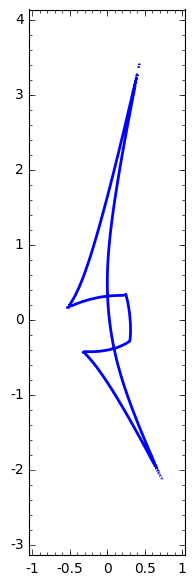

In [124]:
R1.<x0,x1,x2,u0,u1,u2> = QQ['x0,x1,x2,u0,u1,u2']
R2.<u0,u1,u2> = QQ['u0,u1,u2']

G = ideal(dual_curve(F)).change_ring(R2)

P=plot_curve(G)
S=singular_points(G)

print S
print "Degree of dual: ", G.gens()[0].degree()
print "Dimension of singularities: ", S.dimension()-1
print "Number of singularities: ", (S.hilbert_polynomial())
P

We consider a surface $S$ in $\mathbb P^3$ defined by a polynomial $F \in \mathbb R[x_0,x_1,x_2,x_3]$.

In [ ]:
load("visualize.sage")
load("surfaces.sage")

R.<x0,x1,x2,x3> = QQ['x0,x1,x2,x3']
X = matrix(R,[[x0],[x1],[x2],[x3]])

## Define F
M0 = random_matrix(ZZ,1,4)
M1 = random_matrix(ZZ,1,4)
M2 = random_matrix(ZZ,1,4)
M3 = random_matrix(ZZ,1,4)
N1 = random_matrix(ZZ,4,4)
N2 = random_matrix(ZZ,4,4)

#F = (M0*X)[0,0]*x0*x1*x2+(M1*X)[0,0]*x0*x1*x3+(M2*X)[0,0]*x0*x2*x3+(M3*X)[0,0]*x1*x2*x3+(
#(X.transpose()*N1*X)[0,0]*(X.transpose()*N2*X)[0,0])
F = (X.transpose()*N1*X)[0,0]*x0+x2*x3^2+x2^3

F = general_surface(2)
S=ideal(F)
F

In [ ]:
plotSurf(F)

Let's verify that $S$ is smooth:

In [ ]:
J=jacobian(F,(x0,x1,x2,x3))
SingularLocus=S+ideal(J.list())
print(SingularLocus.subs(x0=1).primary_decomposition())
print(SingularLocus.subs(x1=1).primary_decomposition())
print(SingularLocus.subs(x2=1).primary_decomposition())
print(SingularLocus.subs(x3=1).primary_decomposition())

We can also look at the dual $S^\vee$ in $(\mathbb P^3)^*$.

In [ ]:
R1.<x0,x1,x2,x3,u0,u1,u2,u3> = QQ['x0,x1,x2,x3,u0,u1,u2,u3']
Dual = dual_surface(S, R1)
Dual

We consider the outline of $S$ from a viewpoint $c$.

In [ ]:
R2.<x0,x1,x2,x3,u0,u1,u2> = QQ['x0,x1,x2,x3,u0,u1,u2']

P = vector([1,0,0,0])
ProjMatrix = matrix([[-P[1],P[0],0,0],[-P[2],0,P[0],0],[-P[3],0,0,P[0]]])
ProjMatrix

X = matrix(R2, [[x0], [x1], [x2], [x3]])
U = matrix(R2, [[u0],[u1],[u2]])
S = S.change_ring(R2)

IncidenceIdeal = S + ideal((ProjMatrix*X).augment(U).minors(2))
IncidenceIdeal = S + ideal((ProjMatrix*X-U).list())

Ramification = IncidenceIdeal + ideal(jacobian(IncidenceIdeal.gens(),(x0,x1,x2,x3)).minors(4))

Outline = Ramification.saturation(ideal(x0, x1, x2, x3))[0]
Outline = Outline.elimination_ideal((x0, x1, x2, x3))

Outline = Outline.subs(u0=1).change_ring(QQ['u1,u2'])

s = singular.eval
s('LIB "surf.lib";')
s("ring r = 0,(u1,u2),dp;")
s("plot("+str(Outline.gens()[0])+")")

Outline.plot()

# Outline


We now consider a *variable* viewpoint $c$.

In [ ]:
R3.<x0,x1,x2,x3,u0,u1,u2,c0,c1,c2,c3> = QQ['x0,x1,x2,x3,u0,u1,u2,c0,c1,c2,c3']

P = vector([c0,c1,c2,c3])
ProjMatrix = matrix([[-P[1],P[0],0,0],[-P[2],0,P[0],0],[-P[3],0,0,P[0]]])
ProjMatrix

X = matrix(R3, [[x0], [x1], [x2], [x3]])
U = matrix(R3, [[u0],[u1],[u2]])
S = S.change_ring(R3)

IncidenceIdeal = S + ideal((ProjMatrix*X).augment(U).minors(2))
IncidenceIdeal = S + ideal((ProjMatrix*X-U).list())

Ramification = IncidenceIdeal + ideal(jacobian(IncidenceIdeal.gens(),(x0,x1,x2,x3)).minors(4))

Outline = Ramification.saturation(ideal(x0, x1, x2, x3))[0]
Outline = Outline.elimination_ideal((x0, x1, x2, x3))

#Outline.primary_decomposition()

In [ ]:
s = singular.eval
s('LIB "surf.lib";')
s("ring r = 0,(x,y),dp;")
s("plot(x^2-y^3)")

In [209]:
maxima.plot2d('cos(2*x) + 2*exp(-x)','[x,0,1]','[plot_format,openmath]')

In [2]:
2+2

4

[   1 1/20    0    0]
[   0 1/20    1    0]
[   0    0    0    1]
Ideal (1638400000000*u0^6*u2^2 - 4915200000000*u0^4*u1*u2^3 - 150680960000*u0^4*u2^4 + 4915200000000*u0^2*u1^2*u2^4 - 29134080000*u0^3*u2^5 + 39155200000*u0^2*u1*u2^5 - 1638400000000*u1^3*u2^5 - 2206216400*u0^2*u2^6 + 3939840000*u0*u1*u2^6 - 1848320000*u1^2*u2^6 - 77513076*u0*u2^7 + 108918716*u1*u2^7 - 1073141*u2^8) of Multivariate Polynomial Ring in x, y, z, t, u0, u1, u2 over Rational Field


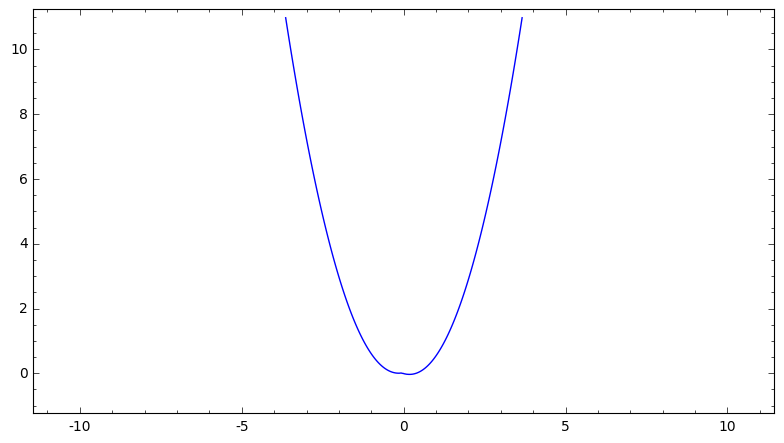

In [318]:
R.<x,y,z,t,u0,u1,u2>=QQ[]
surface = z-(x^2+x*y+y^4)
#s = singular.eval
#s('LIB "surf.lib";')
#s("ring r = 0,(x,y,z),dp;")
#s("surfer(" + str(surface) + ")")

surface_h = surface.homogenize(t)

X = matrix(R, [[x], [y], [z], [t]])
U = matrix(R, [[u0],[u1],[u2]])

# projection:
s=.05
r=10
proj_matrix = matrix(QQ, [[1,s,0,0],[0,s,1,0],[0,0,0,1]])
print(proj_matrix)

incidence = surface_h + ideal((proj_matrix*X).augment(U).minors(2))
incidence = surface_h + ideal(((proj_matrix*X)-U).list())

ramification = incidence + ideal(jacobian(incidence.gens(),(x,y,z,t)).minors(4))

outline = ramification.saturation(ideal(x,y,z,t))[0]
outline = outline.elimination_ideal((x,y,z,t))

print(outline)
outline=outline.subs(u2=1)
(outline.change_ring(QQ[u0,u1])).plot(plot_points=1000)#,algorithm='surf')

In [ ]:
(outline.change_ring(QQ[u0,u1])).plot

In [ ]:
(outline.change_ring(QQ[u0,u1])).plot

In [ ]:
outline=outline.subs

In [142]:
sines = [plot(c*sin(x), (-2*pi,2*pi), color=Color(c,0,0), ymin=-1, ymax=1) for c in sxrange(0,1,.2)]
a = animate(sines)
a.save('test_animation.gif')

In [150]:
R.<x,y>=QQ[]
curve = ideal(y-x^3)
curve.plot(algorithm="surf",linewidth=50)

In [328]:
# condition for a polynomial to have 2+2 multiplicity/ have 3 multiplicity/ 

# for surfaces: conditions for a polynomial to have 4 multiplicity (flecnodal)
# have 3+2, 2+2+2 (ok). Intersection with plane: 3+ramification on y, 2+2+ramification on y

In [81]:
# subresultant
R.<s,t>=QQ[]

poly0 = s^2*t^4+t+3 
poly1 = s*t^3+s*t^2

poly0=poly0.polynomial(t)
poly1=poly1.polynomial(t)


print subresultant_2(poly0,poly1)

#show(poly.sylvester_matrix(poly.derivative(t), t))

subres = (poly.sylvester_matrix(poly.derivative(t), t)).delete_rows([2,6])
subres = subres.delete_columns([6])
#show(subres)

subres.nrows(),subres.ncols()

condition1 = subres.delete_columns([5]).determinant()
condition2 = subres.delete_columns([4]).determinant()

(3*s^2, s^2, s^4)


In [67]:
M=poly0.sylvester_matrix(poly1)
M.delete_rows?

In [ ]:
(poly0.sylvester_matrix(poly1)).delete_rows

In [62]:
poly0.sylvester_matrix(poly1).delete_rows(?)

SyntaxError: invalid syntax (<ipython-input-62-7debf33a83f8>, line 1)

In [ ]:
poly0.sylvester_matrix(poly1).delete_rows

In [4]:
R.<d>=QQ[]
S.<t1,t2>=R[]

In [20]:
d*t1*((d-1)*t1+t2)*((d-2)*t1+2*t2)#*((d-3)*t1+3*t2)

(d^3 - 3*d^2 + 2*d)*t1^3 + (3*d^2 - 4*d)*t1^2*t2 + 2*d*t1*t2^2

TypeError: no conversion of this ring to a Singular ring defined